# PathSnap — Model 3: K-Nearest Neighbours (executed)
**Owner:** Pandu

CV: 5-fold GroupKFold by trip on 80 train trips. Test: 10 student_test trips. Primary metric: observation-level Top-1 accuracy.

**Pipeline:** raw GPS → metres → 8 candidate road segments per GPS point → 14 features → classifier P(true road) → HMM/Viterbi.

*This notebook was executed end to end; every output below is the real result of running the cell.*

## Step 1 — Setup
**What we say:** The notebook runs our repository code from `src/`, so its results match the repo.

In [1]:
# Works on Google Colab (clones repo, data from Drive) or locally inside the repo
import os, sys
try:
    import google.colab  # noqa
    from google.colab import drive; drive.mount('/content/drive')
    !git clone -q https://github.com/GTX-Pradeep/Path_Snap_PT_096.git /content/pathsnap
    !pip install -q lightgbm pyarrow folium
    os.environ['PATHSNAP_DATA'] = '/content/drive/MyDrive/Student folder'   # <- upload dataset here
    os.chdir('/content/pathsnap/src')
except ImportError:
    os.chdir(os.path.join(os.path.dirname(os.path.abspath('.')), 'src') if os.path.basename(os.path.abspath('.')) == 'notebooks' else 'src')
sys.path.insert(0, '.')
print('working dir:', os.getcwd())

working dir: /home/user/pathsnap/src


## Step 2 — Load the candidate dataset
**What we say:** One row per (GPS point, candidate arc) with 14 features. Label = 1 if it is the reference arc. Training points with an unreliable reference (more than 50 m away) are removed; student_test is never filtered.

In [2]:
import os, pandas as pd
if not os.path.exists('../results/candidates_student_test.parquet'):
    !python build_dataset.py
from train_models import load_tables
from features import FEATURES
tr, te = load_tables()
print('train rows (obs with reference >50 m removed):', len(tr), '| trips:', tr.trip.nunique())
print('student_test rows:', len(te), '| trips:', te.trip.nunique())
print('positive rate train: %.3f' % tr.label.mean())
tr[['trip','obs','arc'] + FEATURES[:6] + ['label']].head()

train rows (obs with reference >50 m removed): 1383341 | trips: 80
student_test rows: 139960 | trips: 10
positive rate train: 0.133


,trip,obs,arc,dist,dist_rank,dist_minus_min,dist_ratio_min,heading_diff,heading_diff_cos,label
0,00000001,0,64973,0.717461,0,0.000000,0.417745,0.022749,0.999741,1
1,00000001,0,117639,15.011181,1,14.293720,8.740331,3.120038,-0.999768,0
2,00000001,0,2641,32.199208,2,31.481746,18.748141,0.024998,0.999688,0
3,00000001,0,50652,92.292524,3,91.575063,53.737759,2.936500,-0.979042,0
4,00000001,0,53932,92.292524,4,91.575063,53.737759,0.205093,0.979042,0


## Step 3 — Train Model 3: K-Nearest Neighbours
**Why this model:** It is instance-based. A candidate is scored by the labels of its **25 most similar training candidates**, weighted by distance. It makes no assumptions about the decision boundary, which makes it a non-parametric reference point.
**Configuration:** StandardScaler (KNN uses distances, so features must share a scale), then KNeighborsClassifier(k=25, weights='distance'). It is fitted on a **300k-row random subsample** because prediction cost grows with the number of stored rows.
**Objective:** none. KNN is a lazy learner; prediction is a distance-weighted vote.
**What to look for:** train F1 = 1.000, because with distance weighting every training row is its own nearest neighbour. That **overfitting** shows clearly against the CV score. Also note the slow inference time.

In [3]:
from train_models import evaluate, MODELS
print(MODELS['knn']['make']())
res = evaluate('knn', tr=tr, te=te)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier',
                 KNeighborsClassifier(n_jobs=-1, n_neighbors=25,
                                      weights='distance'))])
== knn (Instance-based)


  [knn] fold 0: macro F1=0.8865


  [knn] fold 1: macro F1=0.8893


  [knn] fold 2: macro F1=0.9111


  [knn] fold 3: macro F1=0.9227


  [knn] fold 4: macro F1=0.8947


  -> test top1=0.8485 macroF1=0.9069 logloss=0.1470


## Step 4 — Full metrics
**What we say:** The primary metric is **test_top1_accuracy**: for each GPS point, is the best-scoring candidate the reference arc? Log loss measures probability quality, which matters for the HMM.

In [4]:
pd.Series({k: v for k, v in res.items() if k not in ('config','loss_curve','validation_scores','test_confusion_matrix','cv_macro_f1_folds')}).to_frame('value')

,value
model,knn
family,Instance-based
train_rows,300000
cv_macro_f1_mean,0.900836
cv_macro_f1_std,0.013868
train_macro_f1,1.0
test_macro_f1,0.906916
test_precision,0.852346
test_recall,0.825739
test_log_loss,0.146993


## Step 5 — Confusion matrix and overfitting check
**What we say:** Compare train vs CV vs test macro F1. A large train > CV gap means overfitting; all three low means underfitting.

In [5]:
print('Confusion matrix (student_test, threshold 0.5):')
print(pd.DataFrame(res['test_confusion_matrix'], index=['true 0','true 1'], columns=['pred 0','pred 1']))
print('\nCV folds macro F1:', [round(x, 4) for x in res['cv_macro_f1_folds']])
print('train F1 %.3f | CV F1 %.3f | test F1 %.3f' % (res['train_macro_f1'], res['cv_macro_f1_mean'], res['test_macro_f1']))

Confusion matrix (student_test, threshold 0.5):
        pred 0  pred 1
true 0  118137    2731
true 1    3327   15765

CV folds macro F1: [0.8865, 0.8893, 0.9111, 0.9227, 0.8947]
train F1 1.000 | CV F1 0.901 | test F1 0.907


## Step 6 — Diagnostic plots

saved /home/user/pathsnap/results/plots/knn_diagnostics.png


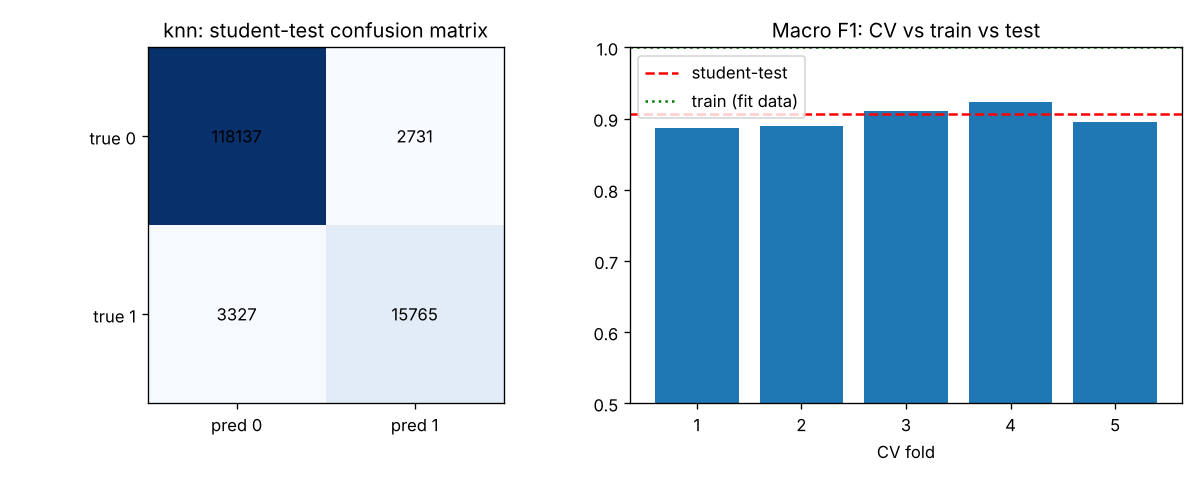

In [6]:
!python plot_results.py knn
from IPython.display import Image
Image('../results/plots/knn_diagnostics.png')

## Step 7 — Comparison with all models

In [7]:
from train_models import comparison_table
comparison_table()

,model,family,cv_macro_f1_mean,cv_macro_f1_std,train_macro_f1,test_macro_f1,test_precision,test_recall,test_log_loss,test_top1_accuracy,train_time_s,inference_time_s
2,lgbm_tuned,Boosting (Bayesian-tuned),0.913226,0.017545,0.933301,0.918469,0.869194,0.848890,0.091774,0.863727,18.340475,1.628193
1,lgbm,Boosting,0.888708,0.017883,0.900048,0.889723,0.710384,0.954955,0.141915,0.860386,10.324093,0.541689
4,mlp,Neural network,0.907300,0.017159,0.914204,0.915676,0.867549,0.840876,0.099219,0.856472,21.219929,0.051044
5,rf,Ensemble (bagging),0.894289,0.019878,0.896987,0.897437,0.736392,0.942437,0.139501,0.854906,28.505462,0.204082
0,knn,Instance-based,0.900836,0.013868,1.000000,0.906916,0.852346,0.825739,0.146993,0.848539,0.647524,54.441055
3,logreg,Linear / probabilistic,0.826067,0.012961,0.825726,0.828732,0.582741,0.936256,0.227736,0.847860,7.477051,0.018992
